<a href="https://colab.research.google.com/github/axelvazquezp/LandingPage_AB_Testing_Conversion-Analysis/blob/main/Proyect_Sprint09_Landing_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experimento A/B en página de inicio

El objetivo de este proyecto es evaluar un **experimento A/B** realizado en una página de inicio (landing page) con versiónes **A y B** para apoyar una **decisión de negocio basada en datos**.

---

El archivo `landing_experiment.csv` contiene información de usuarios expuestos a dos versiones de la página de inicio (landing page) dentro del experimento A/B. Incluye región, dispositivo, fuente de tráfico, tipo de usuario, conversión y gasto.

El análisis sigue una lógica clara y progresiva:

1. 🔍 Explorar y validar los datos.

2. 💰 Comparar el **gasto promedio** por usuario entre la página A y B.

3. 🎯 Comparar la **tasa de conversión** entre la página A y B.

4. 🌐 Revisar **la relación entre la fuente de tráfico y la conversión**.

5. 👤 Revisar **la relación entre el tipo de usuario y la conversión**.

6. 📈 **Visualizar los resultados**: Respalda tus conclusiones mediante gráficos claros.

Se aplican **puebas estadísticas apropiados** para comparar las páginas y **recomendar qué versión es mejor**, justificando la decisión con datos.

## 🧩 Paso 1: Cargar y validar los datos

### 1.1 Carga de datos y vista rápida

In [ ]:
# importar librerías
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import ttest_ind
from statsmodels.stats.proportion import proportions_ztest
from scipy.stats import chi2_contingency

In [ ]:
# cargar archivo
df = pd.read_csv('/datasets/landing_experiment.csv')

**Vista previa e información general del conjunto de datos**

In [ ]:
# mostrar las primeras 5 filas
df.head()

,user_id,date,landing,region,dispositivo,traffic_source,user_type,converted,gasto
0,26f3052e-8500-44ea-8fff-06de65258abb,2026-01-01,A,Norte,Mobile,Email,Recurrente,1,38.08
1,92378c09-4bbf-40c7-945e-82b84f392d22,2026-01-23,A,Occidente,Mobile,Organic,Nuevo,0,0.00
2,a4397360-40e5-45d6-a7ff-dcb4da2c9a1f,2026-01-01,B,Centro,Mobile,Organic,Nuevo,0,0.00
3,7ca3a26f-1e6c-44aa-9b09-b8cb01112956,2026-01-22,A,Centro,Mobile,Ads,Nuevo,0,0.00
4,8dc9593b-5b9c-479d-848b-a99493920419,2026-01-16,A,Sur,Mobile,Organic,Nuevo,0,0.00


In [ ]:
# información general
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   user_id         40000 non-null  object 
 1   date            40000 non-null  object 
 2   landing         40000 non-null  object 
 3   region          40000 non-null  object 
 4   dispositivo     40000 non-null  object 
 5   traffic_source  40000 non-null  object 
 6   user_type       40000 non-null  object 
 7   converted       40000 non-null  int64  
 8   gasto           40000 non-null  float64
dtypes: float64(1), int64(1), object(7)
memory usage: 2.7+ MB


 - No existen valores nulos  o ausentes en el dataset.
 - La columna 'date' se encuentra como object por lo que hay convertirla a datetime

In [ ]:
# Cambiar el tipo de dato de la columna 'date'
df['date'] = pd.to_datetime(df['date'])

# Verificar que el cambio se aplicó correctamente
print(df['date'].dtype)

datetime64[ns]


**Descripción del conjunto de datos**

El dataset contiene las siguientes columnas:

- `user_id` — Identificador único del usuario
- `date` — Fecha en la que el usuario fue expuesto a la página
- `landing` — Versión de la página mostrada al usuario
- `region` — Región geográfica del usuario
- `dispositivo` — Tipo de dispositivo utilizado por el usuario
- `traffic_source` — Canal por el que llegó el usuario
- `user_type` — Tipo de usuario según historial previo
- `converted` — Indica si el usuario realizó una conversión
- `gasto` — Monto gastado por el usuario (0 si no convirtió)

### 1.2 Análisis exploratorio y revisión de calidad de datos

Se identifican las variables clave del experimento A/B y se valida que estén bien definidas, completas y que sean consistentes.



 **Variable `user_id`**  
 Verificar usuarios únicos


In [ ]:
df['user_id'].nunique()

40000

 **Variable `date`**  
Explorar rango de fechas

In [ ]:
# Resumen estadístico
df["date"].describe()

count                   40000
unique                     28
top       2026-01-24 00:00:00
freq                     1512
first     2026-01-01 00:00:00
last      2026-01-28 00:00:00
Name: date, dtype: object

In [ ]:
# Identificar rango temporal del experimento
print("Fecha mínima:", df["date"].min())
print("Fecha máxima:", df["date"].max())

Fecha mínima: 2026-01-01 00:00:00
Fecha máxima: 2026-01-28 00:00:00


La duración del experimento es de 28 días

**Variable `gasto` (numérica)**

In [ ]:
# Resumen estadístico
df["gasto"].describe()

count    40000.000000
mean         9.325554
std         25.667986
min          0.000000
25%          0.000000
50%          0.000000
75%          0.000000
max        303.680000
Name: gasto, dtype: float64

In [ ]:
# Resumen estadístico de usuarios que se convirtieron
df[df['converted'] == 1]['gasto'].describe()

count    5706.000000
mean       65.373668
std        30.896545
min        12.120000
25%        42.950000
50%        59.860000
75%        80.370000
max       303.680000
Name: gasto, dtype: float64

 **Variables categóricas**  
 Verificar categorías esperadas del experimento ( A y B).

In [ ]:
# Explorar variables categóricas y cómo se distribuyen
print("\nConteo de categorías:")
columnas_categoricas = ['landing', 'region', 'dispositivo', 'traffic_source', 'user_type']
for col in columnas_categoricas:
    print(f"\nDistribución para la columna: {col} ")
    print(df[col].value_counts())


Conteo de categorías:

Distribución para la columna: landing 
B    20018
A    19982
Name: landing, dtype: int64

Distribución para la columna: region 
Norte        11166
Centro        9613
Sur           8039
Occidente     6398
Oriente       4784
Name: region, dtype: int64

Distribución para la columna: dispositivo 
Mobile     24829
Desktop    15171
Name: dispositivo, dtype: int64

Distribución para la columna: traffic_source 
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64

Distribución para la columna: user_type 
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


- Categorías limpias y bien estructuradas: Las variables cualitativas (landing, region, dispositivo, traffic_source, user_type) muestran únicamente los valores esperados. No se observan duplicados por problemas de mayúsculas/minúsculas ni errores de dedo en la escritura de las categorías.
- Grupos del experimento balanceados: La distribución de la variable landing asigna 20,018 usuarios a la versión B y 19,982 a la versión A. Al ser una división muy cercana de 50/50, el diseño del experimento A/B es estadísticamente sólido.

## 💰 Paso 2: Comparar el gasto promedio por usuario (página A vs B)

Se evalua si existen diferencias estadísticamente significativas en el gasto promedio de los **usuarios que se convirtieron en clientes** entre la página A y la página B, para identificar qué versión genera **mayor valor económico** para el negocio.


In [ ]:
# Gasto por versión
gasto_A = df[(df['landing'] == 'A') & (df['converted'] == 1)]['gasto']
gasto_B = df[(df['landing'] == 'B') & (df['converted'] == 1)]['gasto']

# Verificar cantidad de datos que tiene cada grupo
len(gasto_A), len(gasto_B)

(2512, 3194)

In [ ]:
# Calcular y mostrar el promedio de gasto de cada uno
print("\nGasto promedio por cliente:")
print(f"Página A: ${gasto_A.mean():.2f}")
print(f"Página B: ${gasto_B.mean():.2f}")


Gasto promedio por cliente:
Página A: $61.09
Página B: $68.75


### Prueba T

**Hipótesis:**
- **Hipótesis nula (H₀):** El gasto promedio de los clientes que convirtieron es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):**  El gasto promedio de los clientes que convirtieron es diferente en la página A y en la página B.

In [ ]:
from scipy.stats import levene

# 1. Aplicar la Prueba de Levene para homogeneidad de varianzas
l_stat, p_value_var = levene(gasto_A, gasto_B)

print("Prueba de Homogeneidad de Varianzas (Levene)")
print(f"Estadístico de Levene: {l_stat:.4f}")
print(f"Valor p: {p_value_var:.6f}")

# 2. Automatizar la interpretación para definir el parámetro de la prueba T
alpha = 0.05

if p_value_var < alpha:
    print("\nResultado: Rechazamos la hipótesis nula.")
    print("Conclusión: Hay evidencia de varianzas diferentes en el gasto. Se debe usar (equal_var=False) en la prueba T.")
else:
    print("\nResultado: No rechazamos la hipótesis nula.")
    print("Conclusión: No hay evidencia de varianzas diferentes. Se puede usar (equal_var=True) en la prueba T.")

Prueba de Homogeneidad de Varianzas (Levene)
Estadístico de Levene: 29.1765
Valor p: 0.000000

Resultado: Rechazamos la hipótesis nula.
Conclusión: Hay evidencia de varianzas diferentes en el gasto. Se debe usar (equal_var=False) en la prueba T.


In [ ]:
# Aplicar prueba
z_stat, p_value = ttest_ind(gasto_A, gasto_B, equal_var=False)


# Visualizar resultados
print(f"Estadístico : {z_stat:.4f}")
print(f"Valor p: {p_value:.6e}")

Estadístico : -9.4810
Valor p: 3.627602e-21


In [ ]:
alpha = 0.05   # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")


Rechazamos la hipótesis nula: hay evidencia de una diferencia.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula. El valor p obtenido (3.627602e-21) es extremadamente inferior al umbral de significancia establecido de 0.05 demostrando que la diferencia de montos no se debe a fluctuaciones aleatorias.

**Interpretación de negocio:**  
Con base en una prueba t de dos muestras independientes, encontramos evidencia estadística de una diferencia en el gasto promedio entre las páginas A y B.
En promedio, los usuarios que convirtieron en la página B gastaron más que los de la página A.
Este resultado se basa en una muestra de usuarios que realizaron una compra y no evalúa si la diferencia observada es suficiente para justificar un cambio desde una perspectiva de negocio.

---


## 📈 Paso 3: Comparar la tasa de conversión entre la página A y B

Se evalua si existen diferencias estadísticamente significativas en la **tasa de conversión** entre la página A y B, con el fin de identificar qué versión genera **mayor número de usuarios convertidos**.

### Prueba Z

**Hipótesis:**
- **Hipótesis nula (H₀):** La tasa de conversión es igual en la página A y en la página B.
- **Hipótesis alternativa (H₁):** La tasa de conversión es diferente en la página A y en la página B. Existe una diferencia estadísticamente significativa en la proporción de usuarios que convierten entre ambas versiones.

In [ ]:
# Número de usuarios convertidos por página
convertidos_por_pagina = df.groupby('landing')['converted'].sum()


# Total de usuarios por página
total_por_pagina = df.groupby('landing')['user_id'].count()

print("Usuarios convertidos por página:\n", convertidos_por_pagina)
print("\nTotal de usuarios por página:\n", total_por_pagina)

Usuarios convertidos por página:
 landing
A    2512
B    3194
Name: converted, dtype: int64

Total de usuarios por página:
 landing
A    19982
B    20018
Name: user_id, dtype: int64


In [ ]:
# Aplicar prueba
z_stat, p_value = proportions_ztest(convertidos_por_pagina, total_por_pagina)
# Visualizar resultados
print(f"Estadístico z: {z_stat:.4f}")
print(f"Valor p: {p_value:.6e}")


alpha = 0.05  # umbral de significancia
if p_value < alpha:
    print("Rechazamos la hipótesis nula: hay evidencia de una diferencia.")
else:
    print("No rechazamos la hipótesis nula: no hay evidencia suficiente de una diferencia.")

Estadístico z: -9.6774
Valor p: 3.762977e-22
Rechazamos la hipótesis nula: hay evidencia de una diferencia.


### 📝 Conclusión e interpretación

**Decisión:**  
Se rechaza la hipótesis nula. El valor p obtenido es ampliamente inferior al nivel de significancia estipulado (0.05), lo que demuestra que la diferencia en las tasas de conversión es real y no es producto del azar.

**Interpretación de negocio:**  
Con base en una prueba z para dos proporciones independientes, encontramos evidencia estadística de una diferencia en la tasa de conversión entre las páginas A y B.
En promedio, la página B logró una tasa de conversión superior a la de la página A.
Este resultado se basa en una muestra de usuarios expuestos al experimento y no evalúa si la diferencia observada es suficiente para justificar un cambio desde una perspectiva de negocio.

## 🔗 Paso 4: Revisar la relación entre la fuente de tráfico y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre la **fuente de tráfico** (`traffic_source`) y la **conversión** (`converted`), para identificar qué canales generan más conversiones.

### Prueba Chi

**Hipótesis:**
- **Hipótesis nula (H₀):** La fuente de tráfico (traffic_source) y la conversión (converted) son independientes. El canal por el cual llega un usuario no tiene ninguna relación ni influencia sobre su probabilidad de convertir.
- **Hipótesis alternativa (H₁):** La fuente de tráfico (traffic_source) y la conversión (converted) son dependientes.

In [ ]:
print(df["user_id"].duplicated().sum())
print(df["user_id"].nunique())
print(df['traffic_source'].unique())
print(df['traffic_source'].value_counts())

0
40000
['Email' 'Organic' 'Ads' 'Referral']
Organic     17987
Ads         11935
Email        6123
Referral     3955
Name: traffic_source, dtype: int64


No aplican ninguno de los 2 supuestos que invalidarían la prueba Chi.

In [ ]:
tabla = pd.crosstab(df['traffic_source'], df['converted'])

print("Tabla de Contingencia (Tráfico vs Conversión)")
print(tabla)

Tabla de Contingencia (Tráfico vs Conversión)
converted           0     1
traffic_source             
Ads             10176  1759
Email            5205   918
Organic         15507  2480
Referral         3406   549


In [ ]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla)

print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

alpha = 0.05
if p_value < alpha:
    print("\nResultado: Rechazamos la hipótesis nula.")
    print("Conclusión: Hay evidencia de una asociación significativa entre la fuente de tráfico y la conversión.")
else:
    print("\nResultado: No rechazamos la hipótesis nula.")
    print("Conclusión: No hay evidencia de una relación entre la fuente de tráfico y la conversión.")

Estadístico chi-cuadrado: 8.662
Valor P: 0.034
Grados de libertad: 3

Frecuencias esperadas:
[[10232.47225  1702.52775]
 [ 5249.55405   873.44595]
 [15421.15445  2565.84555]
 [ 3390.81925   564.18075]]

Resultado: Rechazamos la hipótesis nula.
Conclusión: Hay evidencia de una asociación significativa entre la fuente de tráfico y la conversión.


In [ ]:
pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100

converted,0,1
traffic_source,,
Ads,85.261835,14.738165
Email,85.007349,14.992651
Organic,86.212264,13.787736
Referral,86.118837,13.881163


### 📝 Conclusión e interpretación

**Decisión:**  
El valor P obtenido (0.034) es inferior al nivel de significancia establecido (0.05), confirmando que la relación entre el canal de procedencia y la conversión es estadísticamente significativa.

**Interpretación de negocio:**  
Con base en el chi test, encontramos evidencia estadística de que la conversión está asociada a la fuente de tráfico.
En particular, los usuarios que llegan a través de Email y Ads muestran una mayor tasa de conversión que los que provienen de canales Organic y Referral, a pesar de que el tráfico Organic representa el mayor volumen absoluto de visitas.
Este resultado se basa en una muestra de usuarios y no implica causalidad directa ni evalúa si esta diferencia observada es suficiente para justificar una reasignación de presupuesto desde una perspectiva de negocio.


<div class="alert alert-block alert-success">
<b>Comentario del revisor. (Iteración 1)</b> <a class="tocSkip"></a>

✅ Chi-cuadrado correcto, con buena verificación previa de los supuestos de la prueba.
</div>

## 👤 Paso 5: Revisar la relación entre el tipo de usuario y la conversión

Se analiza si existe una **asociación estadísticamente significativa** entre el **tipo de usuario** (`user_type`) y la **conversión** (`converted`), entendiendo que un usuario recurrente puede haber visitado antes sin necesariamente convertirse en cliente en esta ocasión.

El objetivo es identificar qué perfiles muestran mayor probabilidad de conversión dentro del contexto analizado.

### Prueba Chi

**Hipótesis:**
- **Hipótesis nula (H₀):** El tipo de usuario (user_type) y la conversión (converted) son independientes. Que un usuario sea nuevo o recurrente no tiene ninguna relación ni influencia sobre su probabilidad de convertir en esta sesión.
- **Hipótesis alternativa (H₁):**  El tipo de usuario (user_type) y la conversión (converted) están asociados. Existe una relación estadísticamente significativa, lo que indica que el perfil del usuario influye en su probabilidad de conversión.

In [ ]:
print(df["user_id"].duplicated().sum())
print(df["user_id"].nunique())
print(df['user_type'].unique())
print(df['user_type'].value_counts())

0
40000
['Recurrente' 'Nuevo']
Nuevo         26033
Recurrente    13967
Name: user_type, dtype: int64


No aplican ninguno de los 2 supuestos que invalidarían la prueba Chi.

In [ ]:
tabla_user = pd.crosstab(df['user_type'], df['converted'])

print("Tabla de Contingencia (Tipo de usuario vs Conversión)")
print(tabla_user)

Tabla de Contingencia (Tipo de usuario vs Conversión)
converted       0     1
user_type              
Nuevo       22295  3738
Recurrente  11999  1968


In [ ]:
# Aplicar prueba
chi2_stat, p_value, dof, expected = chi2_contingency(tabla_user)

# 3. Visualizar resultados
print(f"Estadístico chi-cuadrado: {chi2_stat:.3f}")
print(f"Valor P: {p_value:.3f}")
print(f"Grados de libertad: {dof}")
print("\nFrecuencias esperadas:")
print(expected)

# 4. Interpretar resultados
alpha = 0.05
if p_value < alpha:
    print("\nResultado: Rechazamos la hipótesis nula.")
    print("Conclusión: Hay evidencia de una asociación significativa entre el tipo de usuario y la conversión.")
else:
    print("\nResultado: No rechazamos la hipótesis nula.")
    print("Conclusión: No hay evidencia de una relación entre el tipo de usuario y la conversión.")

Estadístico chi-cuadrado: 0.513
Valor P: 0.474
Grados de libertad: 1

Frecuencias esperadas:
[[22319.39255  3713.60745]
 [11974.60745  1992.39255]]

Resultado: No rechazamos la hipótesis nula.
Conclusión: No hay evidencia de una relación entre el tipo de usuario y la conversión.


In [ ]:
pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100

converted,0,1
user_type,,
Nuevo,85.641301,14.358699
Recurrente,85.909644,14.090356



### 📝 Conclusión e interpretación

**Decisión:**  
No se rechaza la hipótesis nula . El valor P obtenido (0.474) es ampliamente superior al nivel de significancia establecido (0.05). Esto demuestra que no existe una asociación estadísticamente significativa entre el tipo de usuario y la conversión; es decir, cualquier pequeña variación observada se debe completamente al azar.

**Interpretación de negocio:**  
Con base en el chi test de independencia, encontramos evidencia estadística de que la conversión no está asociada al tipo de usuario.
Al observar las tasas normalizadas, se confirma que tanto los usuarios Nuevos (14.36%) como los Recurrentes (14.09%) convierten prácticamente al mismo ritmo, con una diferencia de apenas el 0.27%. Esto significa que el historial previo del usuario en el sitio no altera su probabilidad de compra en esta sesión.
Este resultado se basa en una muestra de usuarios y no implica causalidad directa ni evalúa si esta falta de diferencia observada es suficiente para justificar un cambio en las estrategias de retención o adquisición desde una perspectiva de negocio.


## 📊 Paso 6: Visualizar los resultados de variables categóricas

Se explora visualmente la relación entre variables categóricas (`traffic_source` y `user_type`) y la conversión, mostrando para cada categoría:
- la cantidad absoluta de usuarios que convirtieron y no convirtieron,
- la proporción de usuarios que convirtieron y no convirtieron.

Esto permite analizar tanto el impacto en volumen como la efectividad relativa de cada categoría y reforzar los resultados obtenidos en las pruebas estadísticas.

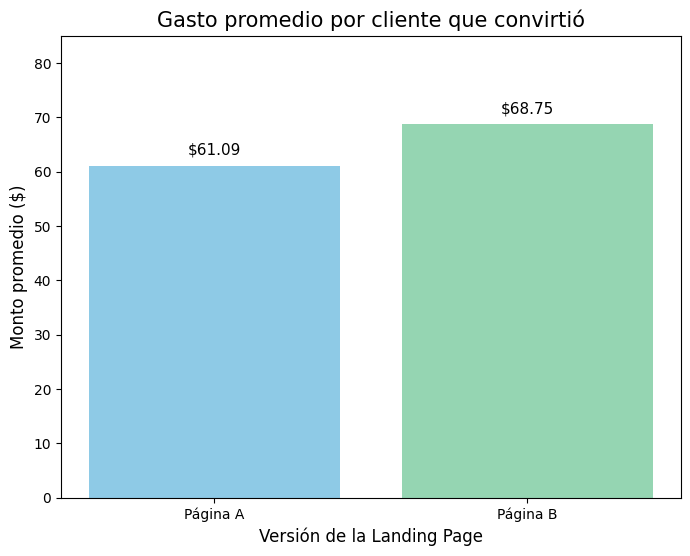

In [ ]:
# Gráfico gasto promedio por cliente que convirtió (A vs B)
versiones = ['Página A', 'Página B']
gastos_promedio = [61.09, 68.75]

plt.figure(figsize=(8, 6))
bars = plt.bar(versiones, gastos_promedio, color=["#8ecae6", "#95d5b2"])

for bar in bars:
    height = bar.get_height()
    plt.text(x=bar.get_x() + bar.get_width()/2,
             y=height + 1.5,
             s=f"${height:.2f}",
             ha='center', va='bottom', fontsize=11)

plt.title('Gasto promedio por cliente que convirtió', fontsize=15)
plt.ylabel('Monto promedio ($)', fontsize=12)
plt.xlabel('Versión de la Landing Page', fontsize=12)
plt.ylim(0, 85)

plt.show()

- La versión de la Landing B superó a la versión A, alcanzando un gasto promedio por cliente de 68.75 frente a los 61.09 de la versión A.

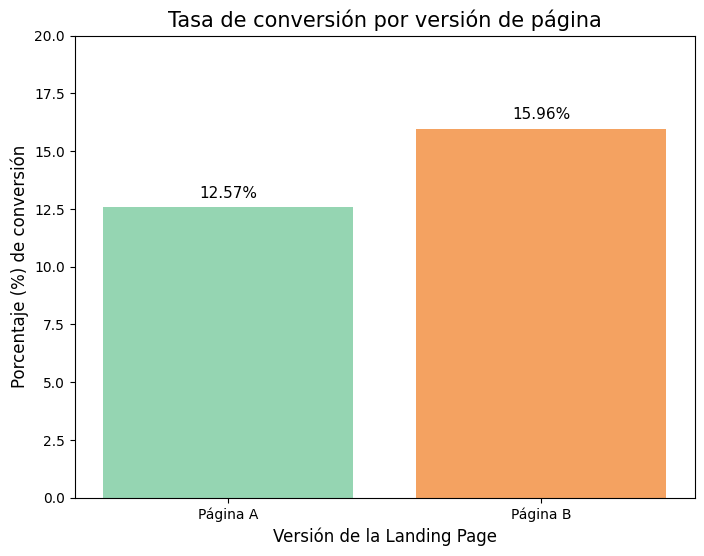

In [ ]:
# Gráfico: Tasa de conversión por Landing Page (A vs B)
# Datos reales de tu experimento
versiones = ['Página A', 'Página B']
tasas_conversion = [12.57, 15.96]

plt.figure(figsize=(8, 6))
bars = plt.bar(versiones, tasas_conversion, color=["#95D5B2", "#F4A261"])

for bar in bars:
    height = bar.get_height()
    plt.text(x=bar.get_x() + bar.get_width()/2,
             y=height + 0.3,
             s=f"{height:.2f}%",
             ha='center', va='bottom', fontsize=11)

plt.title('Tasa de conversión por versión de página', fontsize=15)
plt.ylabel('Porcentaje (%) de conversión', fontsize=12)
plt.xlabel('Versión de la Landing Page', fontsize=12)
plt.ylim(0, 20)

plt.show()

- El Grupo B alcanzó una tasa de conversión del 15.96% (3,194 éxitos de 20,018 usuarios), superando al Grupo A que obtuvo un 12.57% (2,512 éxitos de 19,982 usuarios).

### Relación entre la fuente de tráfico y la conversión

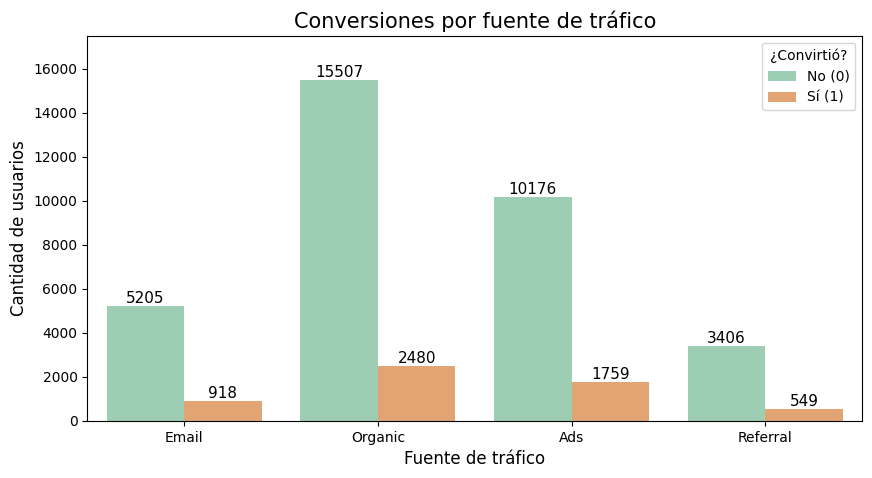

In [ ]:
# Gráfico de barras agrupadas por Fuente de Tráfico
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='traffic_source', hue='converted', palette=["#95D5B2", "#F4A261"])

# Agregar valores
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.text(x=bar.get_x() + bar.get_width() / 2,
                y=height,
                s=int(height),
                ha='center',
                va='bottom',
                fontsize=11)

# Añadir detalles
plt.title('Conversiones por fuente de tráfico', fontsize=15)
plt.xlabel('Fuente de tráfico', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.ylim(0, 17500)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()


- El canal Organic es,, el mayor generador de tráfico hacia el sitio. Registra la mayor cantidad de usuarios que convirtieron (2,480) y que no convirtieron (15,507).
- Los canales de tráfico pagado y directo (Ads y Email) registran una cantidad significativamente menor de visitas totales en comparación con el tráfico orgánico. A pesar de esto, consiguen generar un volumen de conversiones muy competitivo (1,759 y 918 respectivamente).
- El canal Referral se consolida como la fuente de tráfico más débil del ecosistema digital analizado. Aporta únicamente 549 usuarios convertidos frente a un volumen bajo de interacciones totales.
  
El gráfico demuestra que un mayor volumen de visitas no necesariamente se traduce en una efectividad de venta equivalente entre los diferentes canales de captación.

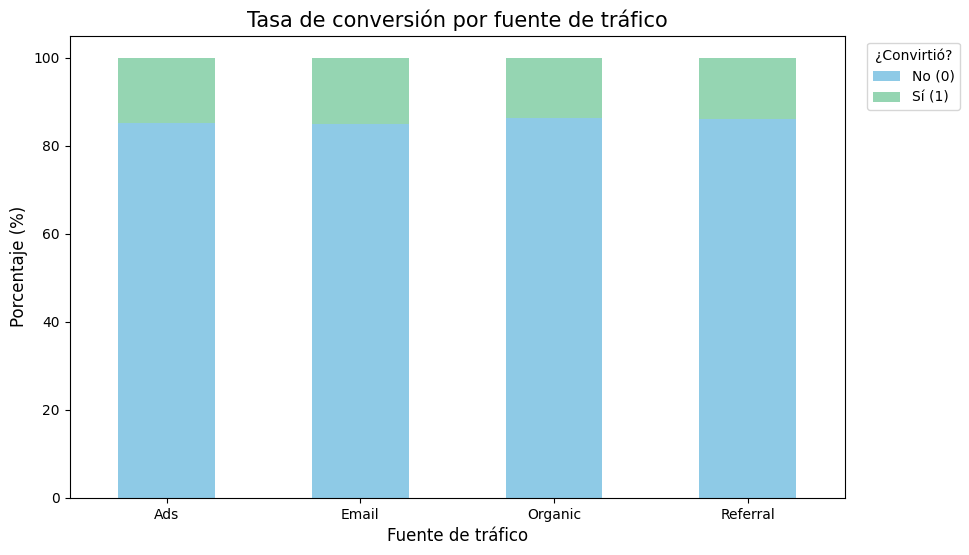

In [ ]:
# 1. Crear tabla cruzada normalizada para Fuentes de Tráfico
tabla_trafico = pd.crosstab(df['traffic_source'], df['converted'], normalize='index') * 100

# 2. Gráfica de barras apiladas
ax = tabla_trafico.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

# Detalles del gráfico
plt.title('Tasa de conversión por fuente de tráfico', fontsize=15)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xlabel('Fuente de tráfico', fontsize=12)
ax.set_xlim(-0.5, 3.5)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper left',  bbox_to_anchor=(1.02, 1))
plt.xticks(rotation=0)
plt.show()

- Las fuentes de tráfico Email (14.99%) y Ads (14.74%) muestran la mayor proporción de usuarios convertidos por cada visita recibida. Tienen una intención de compra más alta.
- El canal Organic presenta la menor tasa de conversión efectiva (13.79%), seguido de cerca por el canal Referral (13.88%). Su composición está más inclinada hacia usuarios que no compran.
- Las tasas de conversión por fuente de tráfico tienen porcentages muy cercanos.

### Relación entre el tipo de usuario y la conversión

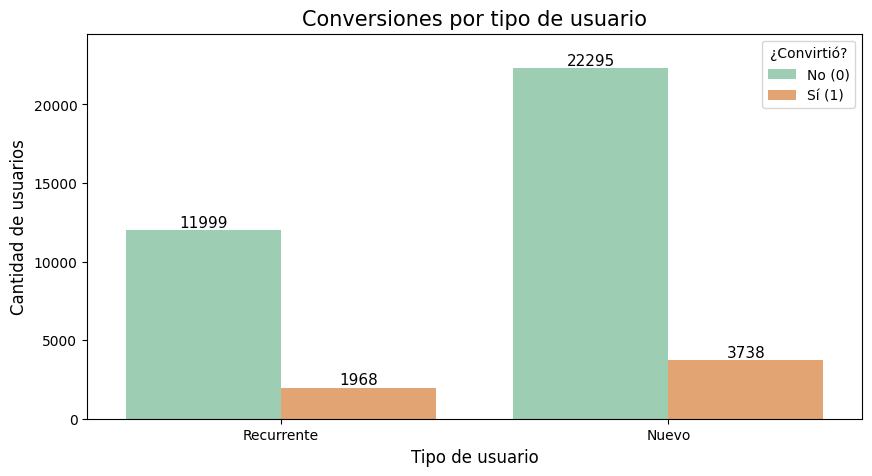

In [ ]:
# Gráfico de barras agrupadas por Tipo de Usuario
plt.figure(figsize=(10, 5))
ax = sns.countplot(data=df, x='user_type', hue='converted', palette=["#95D5B2", "#F4A261"])

# Agregar valores
for bar in ax.patches:
    height = bar.get_height()
    if height > 0:
        ax.text(x=bar.get_x() + bar.get_width() / 2,
                y=height,
                s=int(height),
                ha='center',
                va='bottom',
                fontsize=11)

# Añadir detalles
plt.title('Conversiones por tipo de usuario', fontsize=15)
plt.xlabel('Tipo de usuario', fontsize=12)
plt.ylabel('Cantidad de usuarios', fontsize=12)
plt.ylim(0, 24500)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'])
plt.show()

- La plataforma atrae principalmente a Usuarios Nuevos en volumen absoluto, superando por más del doble a los usuarios recurrentes tanto en el segmento que no convirtió (22,295) como en el que sí lo hizo (3,738).
- Los usuarios clasificados como Recurrentes representan un segmento menor en la muestra, aportando 1,968 compradores y 11,999 visitas sin conversión.

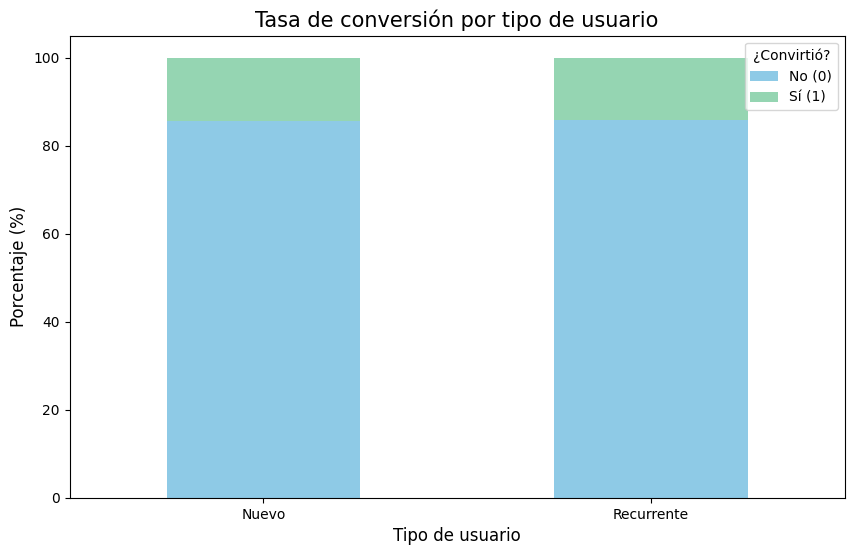

In [ ]:
# 1. Crear tabla cruzada normalizada para Tipo de Usuario
tabla_usuario = pd.crosstab(df['user_type'], df['converted'], normalize='index') * 100

# 2. Gráfica de barras apiladas
ax = tabla_usuario.plot(kind='bar', stacked=True, figsize=(10, 6), color=["#8ecae6", "#95d5b2"])

# Detalles del gráfico
plt.title('Tasa de conversión por tipo de usuario', fontsize=15)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xlabel('Tipo de usuario', fontsize=12)
ax.set_xlim(-0.5, 1.5)
plt.legend(title='¿Convirtió?', labels=['No (0)', 'Sí (1)'], loc='upper right')
plt.xticks(rotation=0)
plt.show()

- La tasa de conversión (franja verde) es prácticamente idéntica entre ambos perfiles, situándose en un 14.36% para los usuarios Nuevos y un 14.09% para los Recurrentes.
- El historial previo del usuario en la plataforma no genera ninguna ventaja ni desventaja en su comportamiento de compra actual.
- Aunque el gráfico anterior demostró que los usuarios nuevos dominan en volumen absoluto, este gráfico de proporciones deja claro que la probabilidad de conversión se mantiene estable e independiente de la familiaridad del usuario con el sitio.



## 🧩 Paso 7. Insight Ejecutivo para Stakeholders

Se traducen los hallazgos del análisis del experimento A/B en conclusiones accionables para el negocio, enfocadas en **versión de página, conversión, gasto promedio, canales de tráfico y tipo de usuario**.

**Preguntas a responder:**  
- ¿Qué página genera mayor conversión y gasto promedio?  
- ¿Qué canales de tráfico son más efectivos para generar conversiones?  
- ¿Existen diferencias significativas según el tipo de usuario?  
- ¿Qué recomendaciones se pueden tomar para optimizar la estrategia de marketing?



---

### 🌟 Insight Ejecutivo basado en el Experimento A/B

#### 🔍 **Comparación de página (A vs B)**  

**Gasto promedio por usuario que convirtió:**
- La versión de la Landing B superó a la versión A, alcanzando un gasto promedio por cliente de 68.75 frente a los 61.09 de la versión A.
- La prueba T de Welch arrojó un valor p contundente (3.627602e-21), confirmando que el incremento en el monto facturado es estadísticamente significativo.
- **Interpretación: La Landing B demuestra una capacidad superior para impulsar transacciones de mayor valor económico, incrementando el ticket promedio de compra por cliente en poco mas de $7 en comparación con la versión A.**

<br>

**Tasa de conversión:**
- El Grupo B alcanzó una tasa de conversión del 15.96% (3,194 éxitos de 20,018 usuarios), superando al Grupo A que obtuvo un 12.57% (2,512 éxitos de 19,982 usuarios).
- La prueba Z para dos proporciones ratificó la validez del experimento con un valor p de 3.762977e-22, descartando por completo el efecto del azar.
- **Interpretación: La versión B es una página de destino más eficiente para guiar al usuario a través del embudo de ventas, aumentando la probabilidad de cierre en 3.39 puntos porcentuales.**

---

#### 📊 **Segmentación por fuente de tráfico**
- Los canales dirigidos de Email (14.99%) y Ads (14.74%) lideran la efectividad de conversión en el sitio, a pesar de que el tráfico Organic aporta el mayor volumen absoluto de visitas (17,987 usuarios).
- La prueba de Chi-cuadrado confirmó una asociación estadísticamente relevante entre el canal de origen y la conversión (p-value: 0.034), demostrando que la procedencia altera la intención de compra.
- **Interpretación:  Los usuarios que llegan por campañas pagadas o correo directo muestran una predisposición de compra superior. El tráfico orgánico es excelente para captar volumen masivo.**

 ---

#### 📊 **Segmentación por tipo de usuario**
- Las tasas de conversión entre usuarios Nuevos (14.36%) y Recurrentes (14.09%) son virtualmente idénticas, mostrando una variación de apenas el 0.27%. Aunque el número total de nuevos usuarios está cerca de duplicar el de los recurrentes.
- La prueba de Chi-cuadrado arrojó un valor P alto (0.474), confirmando que no existe una relación estadística entre el historial del usuario y su probabilidad de conversión.
- **Interpretación: La familiaridad previa con el sitio no influye en la decisión de compra en esta sesión. Ambas audiencias reaccionan con la misma efectividad ante el diseño de la interfaz y la oferta comercial.**

---

Las visualizaciones usadas respaldan los resultados estadísticos de pasos anteriores.

---

#### 💡 **Recomendaciones de negocio:**
- Aunque la versión B demostró con certeza matemática un incremento en la conversión (+3.39 puntos porcentuales) y en el gasto promedio (+12.54%), este hallazgo se limita estrictamente al comportamiento de la muestra. Antes de un lanzamiento global, el equipo debe de determinar si el retorno de inversión esperado justifica la migración e inversión.
-  Dado que el experimento refleja que la procedencia altera el éxito de la página, se recomienda potenciar las campañas de Email y Ads por su alta efectividad relativa. Paralelamente, se debe analizar el tráfico Orgánico para identificar si la landing page está fallando en retener el gran volumen de visitas masivas que recibe, independientemente de la versión que finalmente se decida implementar.